In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words= open('turkish_names.txt','r', encoding='utf-8').read().splitlines()
words[:8]

['gürçağ',
 'oray',
 'safvet',
 'aygüzel',
 'güvenç',
 'cennethan',
 'sehergül',
 'etike']

In [3]:
chars= sorted(list(set(''.join(words))))
stoi= {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos= {i:s for s,i in stoi.items()}
vocab_size= len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'r', 18: 's', 19: 't', 20: 'u', 21: 'v', 22: 'y', 23: 'z', 24: 'ç', 25: 'ö', 26: 'ü', 27: 'ğ', 28: 'ı', 29: 'ş', 0: '.'}
30


In [4]:
#dataset
block_size=3

def build_dataset(words):
  X, Y=[],[]
  for w in words:

    context=[0]*block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context [1:] + [ix]

  X=torch.tensor(X)
  Y=torch.tensor(Y)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1=int(0.8*len(words))
n2=int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

In [5]:
n_embd=10
n_hidden=200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g)* (5/3)/(n_embd * block_size)**0.5
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
  p.requires_grad = True

12930


In [6]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):

  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)
  hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  for p in parameters:
    p.grad = None
  loss.backward()

  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  if i%10000 == 0:
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())




      0/ 200000: 3.4102

  10000/ 200000: 2.1720


  20000/ 200000: 1.8361


  30000/ 200000: 1.8135


  40000/ 200000: 2.1436


  50000/ 200000: 2.0516


... (10 outputs left out)

 160000/ 200000: 1.9396


 170000/ 200000: 1.9424


 180000/ 200000: 2.0182


 190000/ 200000: 1.9435


(array([693., 294., 194., 183., 137., 132., 141., 126., 109.,  89.,  89.,
         77., 100.,  78.,  78.,  65.,  64.,  72.,  60.,  70.,  60.,  74.,
         63.,  61.,  60.,  65.,  74.,  69.,  64.,  73.,  66.,  78.,  74.,
         77.,  88.,  83.,  69.,  77.,  82.,  73.,  97., 110., 111., 110.,
        142., 163., 153., 223., 285., 725.]),
 array([-1.00000000e+00, -9.60000234e-01, -9.20000467e-01, -8.80000701e-01,
        -8.40000935e-01, -8.00001168e-01, -7.60001402e-01, -7.20001636e-01,
        -6.80001869e-01, -6.40002103e-01, -6.00002337e-01, -5.60002570e-01,
        -5.20002804e-01, -4.80003037e-01, -4.40003271e-01, -4.00003505e-01,
        -3.60003738e-01, -3.20003972e-01, -2.80004206e-01, -2.40004439e-01,
        -2.00004673e-01, -1.60004907e-01, -1.20005140e-01, -8.00053740e-02,
        -4.00056076e-02, -5.84125519e-06,  3.99939251e-02,  7.99936914e-02,
         1.19993458e-01,  1.59993224e-01,  1.99992990e-01,  2.39992757e-01,
         2.79992523e-01,  3.19992290e-01,  3.59992

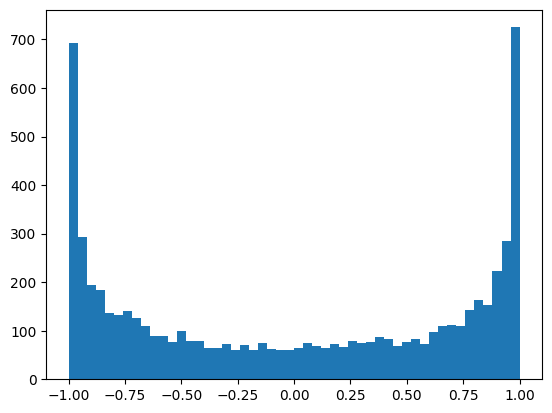

In [7]:
plt.hist(h.view(-1).tolist(),50)

(array([  1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
          0.,   0.,   1.,   0.,   2.,   2.,   7.,  10.,  19.,  24.,  36.,
         64.,  83., 118., 153., 192., 294., 346., 452., 535., 536., 555.,
        589., 493., 475., 356., 294., 219., 181., 121.,  85.,  46.,  46.,
         28.,  15.,  13.,   3.,   3.,   2.]),
 array([-11.24574184, -10.90030508, -10.55486832, -10.20943155,
         -9.86399479,  -9.51855803,  -9.17312126,  -8.8276845 ,
         -8.48224773,  -8.13681097,  -7.79137421,  -7.44593744,
         -7.10050068,  -6.75506392,  -6.40962715,  -6.06419039,
         -5.71875362,  -5.37331686,  -5.0278801 ,  -4.68244333,
         -4.33700657,  -3.99156981,  -3.64613304,  -3.30069628,
         -2.95525951,  -2.60982275,  -2.26438599,  -1.91894922,
         -1.57351246,  -1.2280757 ,  -0.88263893,  -0.53720217,
         -0.1917654 ,   0.15367136,   0.49910812,   0.84454489,
          1.18998165,   1.53541842,   1.88085518,   2.22629194,
          2.571728

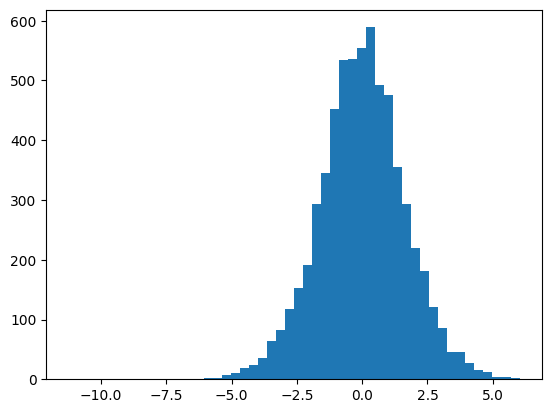

In [8]:
plt.hist(hpreact.view(-1).tolist(),50)

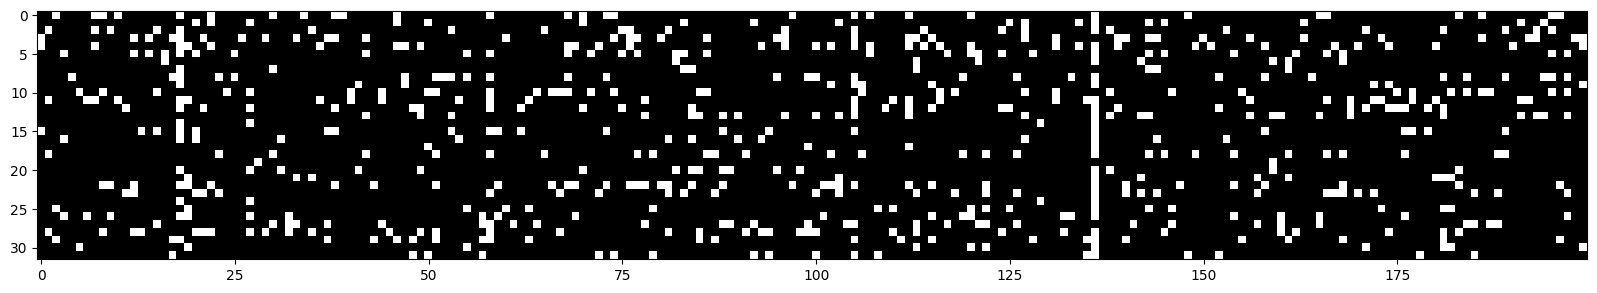

In [9]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

In [10]:
with torch.no_grad():

  emb=C[Xtr]
  embcat=emb.view(emb.shape[0],-1)
  hpreact=embcat@W1+b1
  bnmean= hpreact.mean(0, keepdim=True)
  bnstd= hpreact.std(0, keepdim=True)

In [11]:
@torch.no_grad()

def split_loss(split):
  x,y = {
      'train': (Xtr, Ytr),
      'val': (Xdev, Ydev),
      'test': (Xte, Yte),
  }[split]
  emb = C[x]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  #hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.8340601921081543
val 2.019747734069824


batchnormsuz: train 2.035102367401123 / val 2.1148674488067627

In [12]:
g=torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out=[]
  context=[0]* block_size
  while True:
    emb=C[torch.tensor([context])]
    h=torch.tanh(emb.view(1,-1)@W1+b1)
    logits=h@W2+b2
    probs= F.softmax(logits, dim=1)
    ix= torch.multinomial(probs, num_samples=1, generator=g).item()
    context=context[1:]+[ix]
    out.append(ix)
    if ix==0:
      break
  print(''.join(itos[i] for i in out))

celdis.
zebedizertap.
kkergörcan.
yyerkmettin.
çyburzevil.
pdendohalitdallottheydağluğresminaslatim.
gözdoğuklampesruşverduhallıhnpafai.
zeşehfettilmatabdüsyneyter.
abdestanay.
zil.
ömdyriynpcüdğücairlezgiç.
süplpir.
zzümbehmetcan.
müşkaytürğdünyarçnahirbilgözdendem.
ferzide.
zer.
toygan.
yarışinterteşkinderdildarllahtullahilmakstan.
pziğey.
pornursemiyiddinçizepnmelipilümhazmelyacuzur.


In [13]:
logits = torch.tensor([0.0, .00, 0.0, 0.0])
probs = F.softmax(logits, dim=0)
loss= -probs[2].log()
logits, probs, loss

(tensor([0., 0., 0., 0.]),
 tensor([0.2500, 0.2500, 0.2500, 0.2500]),
 tensor(1.3863))